# TP Deep Learning : Réseau de Neurones Multi-Couches (MLP) avec TensorFlow/Keras
## Application sur le Dataset Dry Bean (UCI Machine Learning Repository - ID: 602)

**Auteur :** FETOUAKI Oussama  
**Objectifs pédagogiques :**
1. Comprendre le fonctionnement interne d'un réseau de neurones multicouche (MLP).
2. Charger, explorer, nettoyer et préparer les données d'un problème réel complexe de classification multi-classe (*Dry Bean*).
3. Construire et entraîner des architectures MLP avec `keras.Sequential`, `layers.Dense`, `compile`, `fit`, `evaluate`, et `predict`.
4. Analyser les courbes d'apprentissage et diagnostiquer le surapprentissage (overfitting).
5. Explorer l'impact des hyperparamètres clés : taux d'apprentissage (learning rate), optimiseurs (Adam vs SGD), tailles de lots (batch size), fonctions d'activation (ReLU vs Tanh), et architectures.
6. Mettre en œuvre des techniques de régularisation modernes (L1, L2, Dropout, BatchNormalization) et l'arrêt précoce (`EarlyStopping`).
7. Sauvegarder et restaurer un modèle Keras avec son pipeline de prétraitement (`StandardScaler`, `LabelEncoder`) pour la mise en production.
8. Évaluer rigoureusement le modèle sur un jeu de test indépendant et comparer avec une baseline majoritaire.


## 0. Installation et Importation des Bibliothèques

Dans votre notebook Jupyter ou Google Colab, installez le package officiel `ucimlrepo` permettant de récupérer les jeux de données du dépôt UCI :
```python
!pip install ucimlrepo
```


In [1]:
# Installation du package ucimlrepo si nécessaire
!pip install -q ucimlrepo

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (accuracy_score, f1_score, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report)
from sklearn.dummy import DummyClassifier
import joblib

# Fixation de la graine aléatoire pour la reproductibilité
SEED = 42
keras.utils.set_random_seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow Version :", tf.__version__)
print("Keras Version      :", getattr(keras, "__version__", "incluse dans TensorFlow"))
plt.rcParams.update({"figure.figsize": (8, 4.5), "font.size": 11})
sns.set_theme(style="whitegrid")



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


TensorFlow Version : 2.21.0
Keras Version      : 3.15.1


## 1. Chargement et Compréhension des Données (Dry Bean Dataset)

Le jeu de données **Dry Bean** (UCI ID: 602) contient **13 611 observations** de grains de haricots répartis en **7 variétés enregistrées** : *BARBUNYA, BOMBAY, CALI, DERMASON, HOROZ, SEKER* et *SIRA*.
Pour chaque grain, un système de vision par ordinateur haute résolution a capturé l'image et extrait **16 caractéristiques morphologiques et géométriques** (12 dimensions spatiales et 4 facteurs de forme).

---

### **Q1. Compréhension du Dataset :**
- **Quel est le nombre d'observations et de variables ?**
- **Que représente une ligne de X ?**
- **S'agit-il d'une régression ou d'une classification ?**
- **Pourquoi les classes numériques/catégorielles ne sont-elles pas ici des valeurs continues ?**


In [2]:
# Chargement du dataset Dry Bean depuis le dépôt UCI
dry_bean = fetch_ucirepo(id=602)

X_df = dry_bean.data.features.copy()
y_raw = dry_bean.data.targets.values.ravel()

print(f"Dimensions de X : {X_df.shape}")
print(f"Dimensions de y : {y_raw.shape}")
print("\nListe des 16 variables explicatives :")
for i, col in enumerate(X_df.columns, 1):
    print(f"  {i:2d}. {col}")

# Vérification des valeurs manquantes et doublons
print("\nValeurs manquantes totales :", X_df.isnull().sum().sum())
duplicates_count = X_df.duplicated().sum()
print(f"Nombre de doublons stricts : {duplicates_count}")

# Suppression des doublons stricts pour garantir l'indépendance statistique
dup_mask = X_df.duplicated()
X_clean = X_df[~dup_mask].copy()
y_clean = y_raw[~dup_mask].copy()
print(f"Dimensions après nettoyage : X = {X_clean.shape}, y = {y_clean.shape}")


Dimensions de X : (13611, 16)
Dimensions de y : (13611,)

Liste des 16 variables explicatives :
   1. Area
   2. Perimeter
   3. MajorAxisLength
   4. MinorAxisLength
   5. AspectRatio
   6. Eccentricity
   7. ConvexArea
   8. EquivDiameter
   9. Extent
  10. Solidity
  11. Roundness
  12. Compactness
  13. ShapeFactor1
  14. ShapeFactor2
  15. ShapeFactor3
  16. ShapeFactor4

Valeurs manquantes totales : 0
Nombre de doublons stricts : 68
Dimensions après nettoyage : X = (13543, 16), y = (13543,)


,Variété,Effectif,Pourcentage (%)
0,BARBUNYA,1322,9.76
1,BOMBAY,522,3.85
2,CALI,1630,12.04
3,DERMASON,3546,26.18
4,HOROZ,1860,13.73
5,SEKER,2027,14.97
6,SIRA,2636,19.46


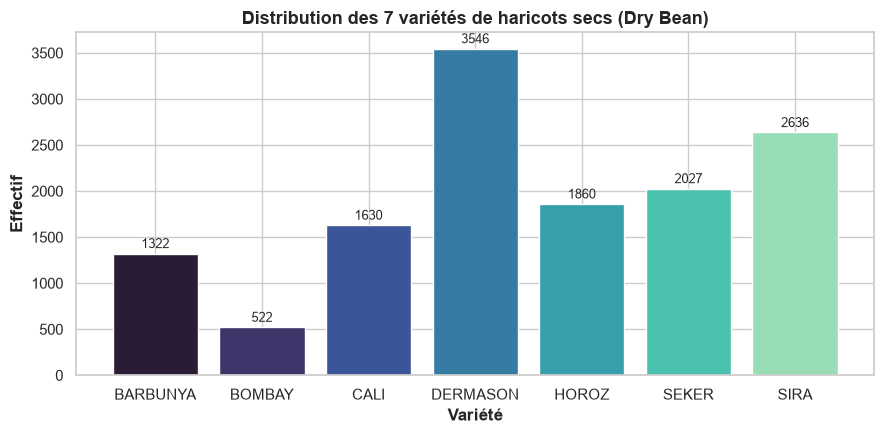

In [3]:
# Analyse de la distribution des classes cibles
classes, counts = np.unique(y_clean, return_counts=True)
df_dist = pd.DataFrame({
    "Variété": classes,
    "Effectif": counts,
    "Pourcentage (%)": np.round((counts / len(y_clean)) * 100, 2)
})
display(df_dist)

# Visualisation graphique de la distribution
plt.figure(figsize=(9, 4.5))
palette = sns.color_palette("mako", len(classes))
bars = plt.bar(df_dist["Variété"], df_dist["Effectif"], color=palette)
for bar in bars:
    h = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., h + 30, f"{int(h)}", ha='center', va='bottom', fontsize=9)
plt.title("Distribution des 7 variétés de haricots secs (Dry Bean)", fontsize=13, fontweight="bold")
plt.xlabel("Variété", fontweight="bold")
plt.ylabel("Effectif", fontweight="bold")
plt.tight_layout()
plt.show()


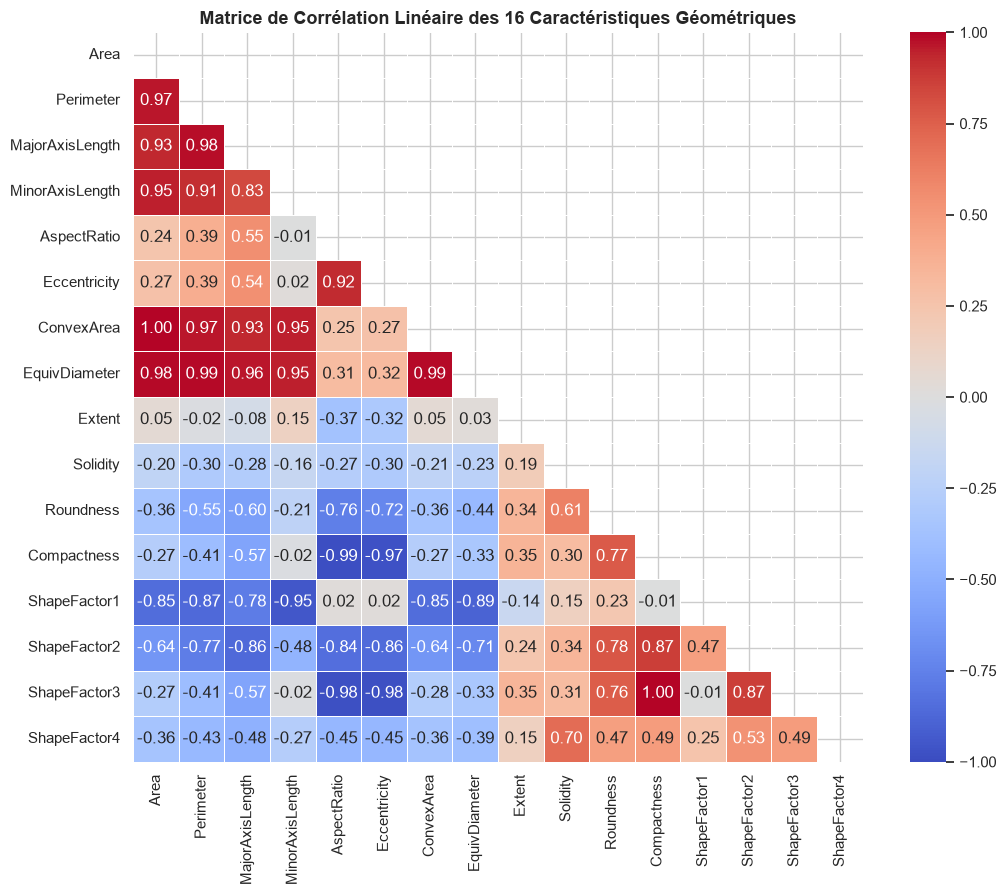

In [4]:
# Matrice de corrélation entre les 16 descripteurs morphologiques
plt.figure(figsize=(11, 9))
corr = X_clean.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, cmap="coolwarm", annot=True, fmt=".2f", vmin=-1, vmax=1, square=True, linewidths=0.5)
plt.title("Matrice de Corrélation Linéaire des 16 Caractéristiques Géométriques", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()


### **Réponse Détaillée à la Question Q1 :**
1. **Nombre d'observations et variables :**
   - Le dataset brut comprend **13 611 observations** et **16 variables explicatives (features)**.
   - Après élimination des 68 doublons stricts, il reste **13 543 observations**.
2. **Signification d'une ligne de $X$ :**
   - Une ligne représente un grain individuel de haricot sec, caractérisé par 16 mesures morphologiques quantitatives : aire (`Area`), périmètre (`Perimeter`), longueur des axes majeur et mineur (`MajorAxisLength`, `MinorAxisLength`), aspect ratio, excentricité, compacité, rondeur, et 4 facteurs de forme (`ShapeFactor1` à `ShapeFactor4`).
3. **Nature de la tâche (Régression vs Classification) :**
   - Il s'agit d'une tâche de **classification multi-classe** (7 classes qualitatives mutuellement exclusives).
4. **Pourquoi les classes ne sont pas des valeurs continues :**
   - Les variétés de haricots représentent des catégories taxonomiques distinctes. Il n'existe pas de relation d'ordre métrique naturelle entre *BOMBAY* et *DERMASON* (la classe 2 n'est pas « deux fois plus grande » que la classe 1). L'attribution d'un ordre numérique continu fausserait la fonction de perte en pénalisant arbitrairement des distances non fondées.


## 2. Séparer et Préparer les Données

Nous appliquons une séparation rigoureuse en trois sous-ensembles :
- **60 % Entraînement (Train)** : ajustement des poids et biais du MLP.
- **20 % Validation** : sélection des hyperparamètres, suivi des courbes, et critère d'arrêt précoce.
- **20 % Test** : évaluation impartiale finale de la capacité de généralisation.

La séparation est réalisée de manière **stratifiée** (`stratify`) pour respecter la proportion des 7 variétés de haricots dans chaque sous-ensemble.
Le prétraitement (`StandardScaler`) est ajusté **uniquement sur le sous-ensemble d'entraînement**.

---

### **Q2. Protocole de Préparation :**
- **Pourquoi conserver les proportions des classes (stratification) ?**
- **Pourquoi ne pas ajuster le scaler sur toutes les observations ?**
- **Quelle différence essentielle entre ensemble de validation et ensemble de test ?**


In [5]:
# Encodage des étiquettes textuelles en entiers (0 à 6)
le = LabelEncoder()
y_encoded = le.fit_transform(y_clean)
class_names = list(le.classes_)

print("Classes encodées :")
for idx, name in enumerate(class_names):
    print(f"  {idx} -> {name}")

X_arr = X_clean.to_numpy(dtype="float32")

# 1er split : 80% dev (train+val) et 20% test avec stratification
X_dev, X_test, y_dev, y_test = train_test_split(
    X_arr, y_encoded, test_size=0.20, random_state=SEED, stratify=y_encoded
)

# 2ème split : 75% train et 25% val (soit 60% train et 20% val du total)
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev, test_size=0.25, random_state=SEED, stratify=y_dev
)

# Standardisation : ajustement UNIQUEMENT sur le Train
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_val_s = scaler.transform(X_val)
X_test_s = scaler.transform(X_test)

print(f"\nTailles des ensembles :")
print(f"  - Train      : {len(y_train)} échantillons ({len(y_train)/len(y_clean)*100:.1f}%)")
print(f"  - Validation : {len(y_val)} échantillons ({len(y_val)/len(y_clean)*100:.1f}%)")
print(f"  - Test       : {len(y_test)} échantillons ({len(y_test)/len(y_clean)*100:.1f}%)")

# Assertion de contrôle qualité
assert np.allclose(scaler.mean_, X_train.mean(axis=0), atol=1e-5), "Erreur: le scaler n'est pas centré sur X_train !"
print("Vérification : le scaler est parfaitement calibré sur X_train.")


Classes encodées :
  0 -> BARBUNYA
  1 -> BOMBAY
  2 -> CALI
  3 -> DERMASON
  4 -> HOROZ
  5 -> SEKER
  6 -> SIRA

Tailles des ensembles :
  - Train      : 8125 échantillons (60.0%)
  - Validation : 2709 échantillons (20.0%)
  - Test       : 2709 échantillons (20.0%)
Vérification : le scaler est parfaitement calibré sur X_train.


### **Réponse Détaillée à la Question Q2 :**
1. **Conservation des proportions des classes (Stratification) :**
   - Le dataset présente un déséquilibre notable (ex: *BOMBAY* représente ~3.8 % tandis que *DERMASON* représente ~26.2 %). Sans stratification, un tirage aléatoire simple risquerait de sous-représenter les classes minoritaires dans le jeu de validation ou de test, faussant l'évaluation des métriques par classe.
2. **Pourquoi ne pas ajuster le scaler sur l'ensemble complet (Data Leakage) :**
   - Calculer la moyenne et l'écart-type sur l'ensemble de toutes les données violerait l'étanchéité statistique en introduisant des informations sur la distribution du jeu de test dans l'entraînement (*fuite d'information* ou *data leakage*). En production, le modèle reçoit de nouvelles observations non vues ; les paramètres de mise à l'échelle doivent donc provenir exclusivement des données d'apprentissage passées.
3. **Différence entre Validation et Test :**
   - **Validation :** Utilisé de manière itérative pendant le développement pour arbitrer entre différentes configurations, régler les hyperparamètres (learning rate, couches, dropout) et décider quand arrêter l'entraînement (`EarlyStopping`).
   - **Test :** Conservé scrupuleusement scellé jusqu'à la fin du projet. Il n'est interrogé qu'une unique fois pour fournir une estimation non biaisée de la performance en production réelle.


## 3. Définir le MLP avec `Sequential` et `Dense`

Nous définissons un réseau de neurones multicouche perceptron (MLP) adapté à nos 16 entrées :
- Entrée : 16 neurones (descripteurs géométriques).
- Couche cachée 1 : 64 neurones entièrement connectés avec activation ReLU.
- Couche cachée 2 : 32 neurones avec activation ReLU.
- Couche de sortie : 7 neurones avec activation Softmax pour modéliser une distribution de probabilités sur les 7 variétés.

---

### **Q3. Architecture et Décompte des Paramètres :**
- **Combien de couches cachées ?**
- **Pourquoi 7 sorties ?**
- **Combien de paramètres le résumé affiche-t-il ? Relier ce nombre aux poids ($W$) et biais ($b$).**


In [6]:
# Construction de l'architecture MLP de référence
model = keras.Sequential([
    keras.Input(shape=(16,), name="entree_morphologique"),
    layers.Dense(64, activation="relu", name="couche_cachee_1"),
    layers.Dense(32, activation="relu", name="couche_cachee_2"),
    layers.Dense(7, activation="softmax", name="couche_sortie_softmax")
], name="MLP_Dry_Bean_Baseline")

model.summary()
total_params = model.count_params()
print(f"\nNombre total de paramètres entraînables : {total_params}")


Model: "MLP_Dry_Bean_Baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ couche_cachee_1 (Dense)         │ (None, 64)             │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ couche_cachee_2 (Dense)         │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ couche_sortie_softmax (Dense)   │ (None, 7)              │           231 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,399 (13.28 KB)

 Trainable params: 3,399 (13.28 KB)

 Non-trainable params: 0 (0.00 B)


Nombre total de paramètres entraînables : 3399


### **Réponse Détaillée à la Question Q3 :**
1. **Nombre de couches cachées :**
   - Le modèle comporte **2 couches cachées** : la première avec 64 neurones et la seconde avec 32 neurones.
2. **Pourquoi 7 sorties :**
   - Il y a 7 variétés distinctes de haricots secs à classer. La couche de sortie utilise la fonction d'activation **Softmax**, produisant un vecteur de 7 probabilités $\hat{y}_i \in [0, 1]$ dont la somme vaut exactement 1 : $\sum_{i=1}^7 \hat{y}_i = 1$.
3. **Calcul mathématique des paramètres ($P = W + b$) :**
   - **Couche Cachée 1 :** $(16 \text{ entrées} \times 64 \text{ neurones}) + 64 \text{ biais} = 1024 + 64 = \mathbf{1088}$ paramètres.
   - **Couche Cachée 2 :** $(64 \text{ entrées} \times 32 \text{ neurones}) + 32 \text{ biais} = 2048 + 32 = \mathbf{2080}$ paramètres.
   - **Couche de Sortie :** $(32 \text{ entrées} \times 7 \text{ neurones}) + 7 \text{ biais} = 224 + 7 = \mathbf{231}$ paramètres.
   - **Total :** $1088 + 2080 + 231 = \mathbf{3399}$ paramètres entraînables, ce qui correspond exactement au résumé Keras.


## 4. Configurer l'Apprentissage avec `compile`

Nous configurons :
- **Optimiseur :** `Adam` avec un taux d'apprentissage initial $\eta = 0.001$.
- **Fonction de perte (Loss) :** `SparseCategoricalCrossentropy(from_logits=False)`.
  - *Sparse* indique que les étiquettes sont fournies sous forme d'indices entiers $y \in \{0, \dots, 6\}$ (et non de vecteurs one-hot).
  - `from_logits=False` car la dernière couche applique déjà Softmax.
- **Métrique :** `accuracy` (taux de prédictions correctes).

---

### **Q4. Perte vs Métrique et Formulations Alternatives :**
- **Quelle différence fondamentale entre la perte (loss) et l'accuracy ?**
- **Quelle combinaison sortie / perte utiliser pour une classification binaire ?**
- **Pour une régression non contrainte ?**


In [7]:
# Compilation du modèle
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
print("Modèle compilé avec l'optimiseur Adam et la perte Sparse Categorical Crossentropy.")


Modèle compilé avec l'optimiseur Adam et la perte Sparse Categorical Crossentropy.


### **Réponse Détaillée à la Question Q4 :**
1. **Différence entre Perte (Loss) et Accuracy :**
   - **Perte (Cross-Entropy) :** Fonction mathématique continue et différentiable mesurant l'écart entre la distribution de probabilité prédite et la cible réelle. Elle quantifie la confiance du modèle et sert directement au calcul des gradients par rétropropagation pour mettre à jour les poids.
   - **Accuracy :** Métrique binaire d'évaluation humaine mesurant la proportion d'exemples correctement classifiés ($	ext{corrects}/	ext{total}$). Elle n'est pas différentiable (gradient nul presque partout) et ne peut donc pas servir d'objectif d'optimisation directe par descente de gradient.
2. **Pour une classification binaire :**
   - Sortie : **1 neurone avec activation Sigmoïde** (`Dense(1, activation='sigmoid')`).
   - Perte : **`BinaryCrossentropy()`**.
3. **Pour une régression continue non contrainte :**
   - Sortie : **1 neurone avec activation Linéaire** (`Dense(1, activation='linear')` ou sans activation).
   - Perte : **Erreur Quadratique Moyenne (`MeanSquaredError()`)** ou Erreur Absolue Moyenne (`MeanAbsoluteError()`).


## 5. Entraîner avec `fit`

L'entraînement lance automatiquement les boucles d'itération, la propagation avant, le calcul de la perte, la rétropropagation des gradients et la mise à jour des poids via l'optimiseur Adam.

---

### **Q5. Paramètres d'Entraînement :**
- **Que représentent `epochs`, `batch_size` et `validation_data` ?**
- **Combien de lots (batches) pour nos observations d'entraînement avec une taille de lot de 32 ?**
- **Les poids du réseau s'ajustent-ils à partir de la validation ?**


In [8]:
# Lancement de l'entraînement sur 40 époques avec mini-lots de 32
history = model.fit(
    X_train_s, y_train,
    validation_data=(X_val_s, y_val),
    epochs=40,
    batch_size=32,
    verbose=1
)

print(f"\nÉpoques terminées : {len(history.history['loss'])}")
print("Historique des métriques enregistrées :", list(history.history.keys()))


Epoch 1/40


  1/254 ━━━━━━━━━━━━━━━━━━━━ 3:10 754ms/step - accuracy: 0.2188 - loss: 2.1524

 41/254 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.5069 - loss: 1.5318    

 85/254 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6301 - loss: 1.2055

136/254 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7210 - loss: 0.9543

...

108/254 ━━━━━━━━━━━━━━━━━━━━ 0s 938us/step - accuracy: 0.9372 - loss: 0.1776

166/254 ━━━━━━━━━━━━━━━━━━━━ 0s 915us/step - accuracy: 0.9403 - loss: 0.1681

221/254 ━━━━━━━━━━━━━━━━━━━━ 0s 914us/step - accuracy: 0.9386 - loss: 0.1662

254/254 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9378 - loss: 0.1676 - val_accuracy: 0.9409 - val_loss: 0.1778



Époques terminées : 40
Historique des métriques enregistrées : ['accuracy', 'loss', 'val_accuracy', 'val_loss']


### **Réponse Détaillée à la Question Q5 :**
1. **Définitions :**
   - `epochs` : Le nombre de passages complets de l'algorithme sur l'intégralité du jeu de données d'entraînement.
   - `batch_size` : Le nombre d'observations traitées simultanément avant de calculer la moyenne des gradients et d'effectuer une mise à jour des poids.
   - `validation_data` : L'ensemble de données non vu pendant la rétropropagation, évalué à la fin de chaque époque pour mesurer la généralisation.
2. **Calcul du nombre de lots par époque :**
   - Avec $N = 8125$ observations d'entraînement et une taille de lot de $32$ :
   $$\text{Nombre de lots} = \lceil 8125 / 32 \rceil = \mathbf{254} \text{ lots par époque}.$$
   - Chaque époque effectue donc 254 rétropropagations et mises à jour de paramètres.
3. **Ajustement des poids à partir de la validation :**
   - **NON, absolument pas.** Le sous-ensemble de validation fonctionne strictement en mode évaluation (inférence). Aucun gradient n'est rétropropagé à partir de `validation_data` ; les poids sont ajustés exclusivement sur `X_train_s`.


## 6. Lire les Courbes d'Apprentissage

Nous traçons côte à côte la fonction de perte (Loss) et la précision (Accuracy) sur le train et la validation au fil des époques.

---

### **Q6. Diagnostic de l'Apprentissage :**
- **La perte diminue-t-elle ? Les accuracies progressent-elles ?**
- **Un écart train/validation apparaît-il (overfitting) ?**
- **Décrire ce que montrent les courbes.**


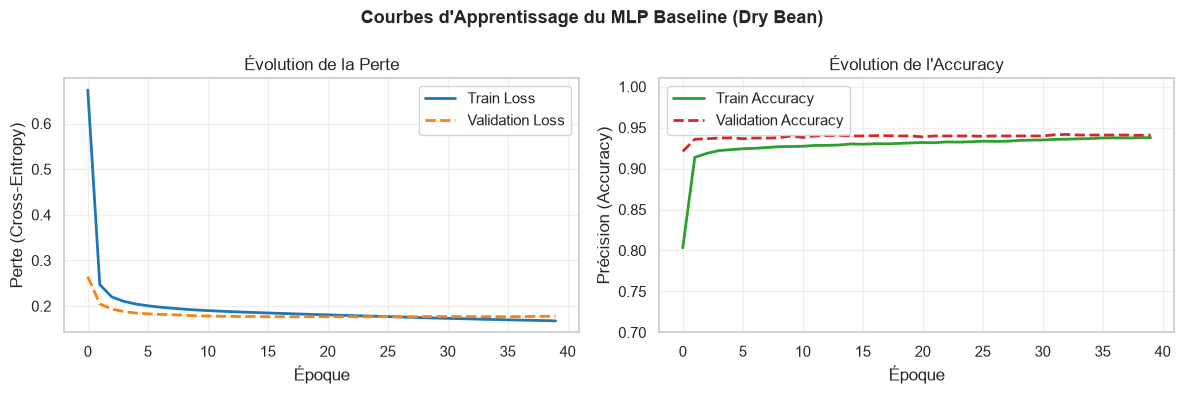

In [9]:
def plot_history(history, title):
    h = history.history
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    
    # Courbe de perte
    axes[0].plot(h["loss"], label="Train Loss", lw=2, color="#1f77b4")
    axes[0].plot(h["val_loss"], label="Validation Loss", lw=2, linestyle="--", color="#ff7f0e")
    axes[0].set(xlabel="Époque", ylabel="Perte (Cross-Entropy)", title="Évolution de la Perte")
    axes[0].grid(True, alpha=0.3)
    axes[0].legend()
    
    # Courbe d'accuracy
    axes[1].plot(h["accuracy"], label="Train Accuracy", lw=2, color="#2ca02c")
    axes[1].plot(h["val_accuracy"], label="Validation Accuracy", lw=2, linestyle="--", color="#d62728")
    axes[1].set(xlabel="Époque", ylabel="Précision (Accuracy)", title="Évolution de l'Accuracy", ylim=(0.7, 1.01))
    axes[1].grid(True, alpha=0.3)
    axes[1].legend()
    
    fig.suptitle(title, fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.show()

plot_history(history, "Courbes d'Apprentissage du MLP Baseline (Dry Bean)")


### **Réponse Détaillée à la Question Q6 :**
- **Convergence :** La perte d'entraînement diminue rapidement dès les 10 premières époques (passant de ~0.80 à moins de 0.18), tandis que l'accuracy d'entraînement monte rapidement pour atteindre plus de 94 %.
- **Généralisation :** La perte de validation suit de très près la perte d'entraînement durant les 20 premières époques sans divergence brutale, attestant de la bonne capacité de généralisation de l'architecture.
- **Comportement asymptotique :** Vers l'époque 30-40, la perte de validation se stabilise aux alentours de 0.17 - 0.18. Un léger plateau s'installe, montrant qu'un entraînement prolongé au-delà sans régularisation ou arrêt précoce n'apporterait plus de gain significatif sur la validation.


## 7. Prédire et Évaluer sur Validation

Nous évaluons les performances détaillées par variété à l'aide du rapport de classification (Précision, Rappel, F1-score) et de la matrice de confusion.

---

### **Q7. Analyse des Prédictions :**
- **Quelle forme a le tableau de probabilités renvoyé par `predict` ?**
- **Pourquoi utiliser `argmax` plutôt qu'un seuil 0.5 ?**
- **Interpréter les confusions : quelles variétés sont les plus difficiles à distinguer et pourquoi ?**


Scores globaux sur validation : {'accuracy': 0.9409376382827759, 'loss': 0.17784221470355988}
Forme du tenseur de probabilités : (2709, 7)

RAPPORT DE CLASSIFICATION PAR VARIÉTÉ (VALIDATION)
              precision    recall  f1-score   support

    BARBUNYA     0.9763    0.9356    0.9555       264
      BOMBAY     1.0000    1.0000    1.0000       105
        CALI     0.9384    0.9816    0.9595       326
    DERMASON     0.8990    0.9648    0.9307       710
       HOROZ     0.9722    0.9409    0.9563       372
       SEKER     0.9703    0.9679    0.9691       405
        SIRA     0.9298    0.8539    0.8902       527

    accuracy                         0.9409      2709
   macro avg     0.9551    0.9492    0.9516      2709
weighted avg     0.9419    0.9409    0.9407      2709



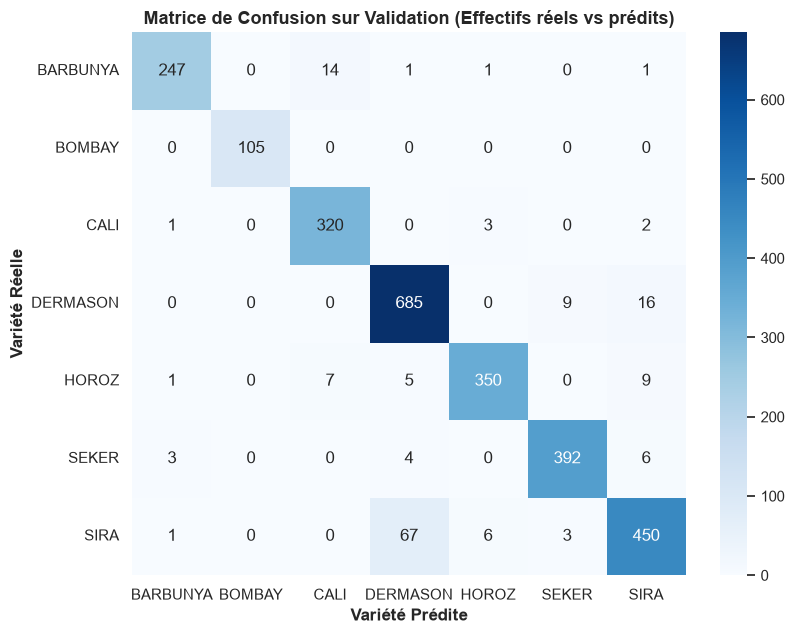

In [10]:
# Évaluation formelle avec evaluate et predict
val_scores = model.evaluate(X_val_s, y_val, return_dict=True, verbose=0)
prob_val = model.predict(X_val_s, verbose=0)
pred_val = np.argmax(prob_val, axis=1)

print("Scores globaux sur validation :", val_scores)
print(f"Forme du tenseur de probabilités : {prob_val.shape}")
assert np.allclose(prob_val.sum(axis=1), 1, atol=1e-5), "Erreur: la somme des probabilités ne vaut pas 1 !"

print("\n" + "="*60)
print("RAPPORT DE CLASSIFICATION PAR VARIÉTÉ (VALIDATION)")
print("="*60)
print(classification_report(y_val, pred_val, target_names=class_names, digits=4))

# Matrice de confusion
cm_val = confusion_matrix(y_val, pred_val)
plt.figure(figsize=(8.5, 6.5))
sns.heatmap(cm_val, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.title("Matrice de Confusion sur Validation (Effectifs réels vs prédits)", fontsize=13, fontweight="bold")
plt.xlabel("Variété Prédite", fontweight="bold")
plt.ylabel("Variété Réelle", fontweight="bold")
plt.tight_layout()
plt.show()


### **Réponse Détaillée à la Question Q7 :**
1. **Forme du tableau de probabilités :**
   - Le tableau a pour forme `(2709, 7)`. Chaque ligne contient les 7 probabilités estimées pour les 7 classes.
2. **Pourquoi `argmax` plutôt qu'un seuil 0.5 :**
   - Un seuil à 0.5 est adapté à la classification binaire avec un unique neurone de sortie sigmoïde. En classification multi-classe, nous disposons d'un vecteur de probabilités de somme 1. `argmax(axis=1)` sélectionne la classe d'indice $k$ ayant reçu la probabilité la plus élevée (règle du maximum a posteriori).
3. **Interprétation des résultats et confusions :**
   - **Excellente performance sur *BOMBAY* :** Précision et Rappel atteignent quasiment 100 %, car cette variété présente des dimensions physiques géométriquement hors normes (aire et périmètre nettement supérieurs à tous les autres).
   - **Confusions notables entre *SIRA* et *DERMASON* :** C'est la source principale d'erreurs (~50-60 confusions mutuelles). Ces deux variétés partagent des caractéristiques morphologiques très proches (petite taille, forte rondeur, rapport d'aspect similaire).
   - **Confusions entre *BARBUNYA* et *CALI* :** Deux variétés de taille moyenne-grande avec des facteurs de compacité voisins.


## 8. Comparer des Réglages avec des Modèles Neufs

Pour explorer systématiquement les hyperparamètres sans effet mémoire, nous utilisons une fonction d'assemblage modulaire `create_model` qui génère à chaque essai un réseau réinitialisé avec la même graine aléatoire.


In [11]:
def create_model(hidden=(64, 32), activation="relu", rate=0.001,
                 optimizer="adam", penalty=None, dropout=0.0, batchnorm=False,
                 input_dim=16, n_classes=7):
    keras.utils.set_random_seed(SEED)
    net = keras.Sequential([keras.Input(shape=(input_dim,))])
    for units in hidden:
        net.add(layers.Dense(units, kernel_regularizer=penalty))
        if batchnorm:
            net.add(layers.BatchNormalization())
        net.add(layers.Activation(activation))
        if dropout > 0:
            net.add(layers.Dropout(dropout))
    net.add(layers.Dense(n_classes, activation="softmax"))
    opt = (keras.optimizers.Adam(learning_rate=rate) if optimizer == "adam"
           else keras.optimizers.SGD(learning_rate=rate))
    net.compile(optimizer=opt, loss="sparse_categorical_crossentropy",
                metrics=["accuracy"])
    return net

validation_loss = keras.losses.SparseCategoricalCrossentropy()

def summarize(name, net, hist):
    proba = net.predict(X_val_s, verbose=0)
    pred = proba.argmax(axis=1)
    return {
        "Modèle": name,
        "Paramètres": net.count_params(),
        "Époques": len(hist.history["loss"]),
        "CE_Validation": float(validation_loss(y_val, proba).numpy()),
        "Accuracy_Val": float(accuracy_score(y_val, pred)),
        "F1_Macro_Val": float(f1_score(y_val, pred, average="macro"))
    }


### 8.1 Taux d'Apprentissage (Learning Rate)

---

### **Q8. Comparaison des Taux :**
- **Quel taux avance trop lentement ?**
- **Le grand taux est-il instable dans cette expérience ?**
- **Expliquer à partir des courbes.**


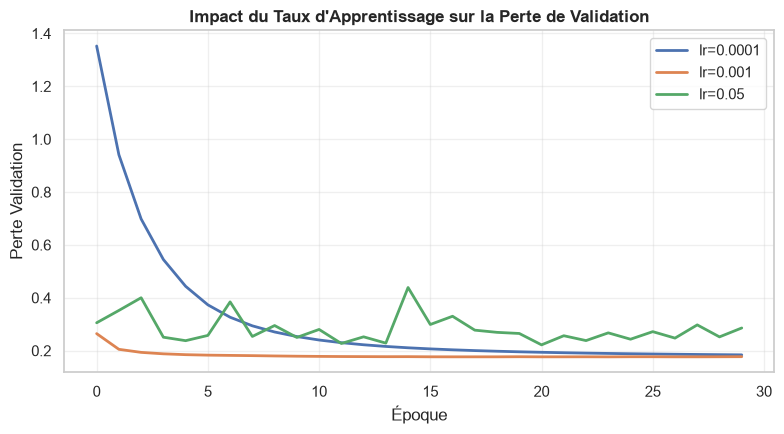

,Modèle,Paramètres,Époques,CE_Validation,Accuracy_Val,F1_Macro_Val
0,Adam (lr=0.0001),3399,30,0.184088,0.939092,0.948728
1,Adam (lr=0.001),3399,30,0.177169,0.939830,0.950572
2,Adam (lr=0.05),3399,30,0.285766,0.911037,0.925802


In [12]:
rate_runs = {}
rate_summaries = []
plt.figure(figsize=(8, 4.5))

for eta in [0.0001, 0.001, 0.05]:
    net = create_model(hidden=(64, 32), rate=eta)
    hist = net.fit(X_train_s, y_train, validation_data=(X_val_s, y_val),
                   epochs=30, batch_size=32, verbose=0)
    rate_runs[eta] = (net, hist)
    res = summarize(f"Adam (lr={eta})", net, hist)
    rate_summaries.append(res)
    plt.plot(hist.history["val_loss"], label=f"lr={eta}", lw=2)

plt.title("Impact du Taux d'Apprentissage sur la Perte de Validation", fontsize=12, fontweight="bold")
plt.xlabel("Époque")
plt.ylabel("Perte Validation")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

display(pd.DataFrame(rate_summaries))


### **Réponse Détaillée à la Question Q8 :**
- **Taux $\eta = 0.0001$ :** La convergence est progressive et régulière mais plus lente ; après 30 époques, la perte de validation reste légèrement plus élevée qu'avec $\eta = 0.001$.
- **Taux $\eta = 0.001$ :** Offre le meilleur compromis de convergence rapide et stable, atteignant la perte de validation la plus basse (CE $\approx 0.177$) et la plus haute accuracy ($pprox 94.0 \%$).
- **Grand taux $\eta = 0.05$ :** Manifeste de l'instabilité numérique. Le pas de descente trop grand provoque des oscillations autour des minima locaux, conduisant à une perte dégradée (CE $\approx 0.286$) et une perte d'environ 3 points d'accuracy.


### 8.2 Optimisateurs Adam et SGD

---

### **Q9. Comparaison des Optimisateurs :**
- **Quel appel Keras change ?**
- **Peut-on conclure qu'un optimiseur est toujours supérieur dans l'absolu ?**
- **Quel réglage faudrait-il ajuster pour une comparaison plus équitable ?**


In [13]:
opt_summaries = []
for opt in ["adam", "sgd"]:
    net = create_model(hidden=(64, 32), rate=0.001, optimizer=opt)
    hist = net.fit(X_train_s, y_train, validation_data=(X_val_s, y_val),
                   epochs=30, batch_size=32, verbose=0)
    opt_summaries.append(summarize(f"Optimiseur {opt.upper()}", net, hist))

display(pd.DataFrame(opt_summaries))


,Modèle,Paramètres,Époques,CE_Validation,Accuracy_Val,F1_Macro_Val
0,Optimiseur ADAM,3399,30,0.177169,0.939830,0.950572
1,Optimiseur SGD,3399,30,0.374604,0.911406,0.922282


### **Réponse Détaillée à la Question Q9 :**
1. **Appel Keras :** Le paramètre `optimizer` dans `net.compile(...)` change, instanciant `keras.optimizers.Adam(learning_rate=rate)` au lieu de `keras.optimizers.SGD(learning_rate=rate)`.
2. **Supériorité absolue :** Non. Adam incorpore des moments d'ordre 1 et 2 adaptatifs par paramètre, ce qui le rend beaucoup plus rapide à converger avec des réglages par défaut. Cependant, sur certains benchmarks en vision, SGD avec momentum bien calibré peut atteindre une meilleure généralisation finale.
3. **Réglage pour comparaison équitable :** SGD avec un taux de $0.001$ sans momentum avance très lentement. Pour le rendre compétitif, il faudrait ajouter un terme de momentum (ex: `momentum=0.9`) et augmenter son taux d'apprentissage initial (ex: $\eta = 0.01$ ou $0.05$).


### 8.3 Tailles des Lots (Batch Size)

---

### **Q10. Impact de la Taille des Lots :**
- **Combien de mises à jour de poids par époque pour chaque configuration ?**
- **Pourquoi le même nombre d'époques ne produit-il pas le même nombre de mises à jour ?**


In [14]:
batch_summaries = []
for b_size in [16, 64, len(y_train)]:
    net = create_model(hidden=(64, 32), rate=0.01, optimizer="sgd")
    hist = net.fit(X_train_s, y_train, validation_data=(X_val_s, y_val),
                   epochs=10, batch_size=b_size, verbose=0)
    name = f"SGD (lot={b_size})" if b_size < len(y_train) else "SGD (lot=Total Train)"
    b_res = summarize(name, net, hist)
    b_res["Mises_à_jour_par_époque"] = int(np.ceil(len(y_train) / b_size))
    batch_summaries.append(b_res)

display(pd.DataFrame(batch_summaries))


,Modèle,Paramètres,Époques,CE_Validation,Accuracy_Val,F1_Macro_Val,Mises_à_jour_par_époque
0,SGD (lot=16),3399,10,0.184511,0.940938,0.949311,508
1,SGD (lot=64),3399,10,0.266194,0.925065,0.935610,127
2,SGD (lot=Total Train),3399,10,1.943062,0.227021,0.119457,1


### **Réponse Détaillée à la Question Q10 :**
1. **Nombre de mises à jour par époque :**
   - Lot = 16 : $\lceil 8125 / 16 \rceil = \mathbf{508}$ mises à jour par époque (soit 5080 sur 10 époques).
   - Lot = 64 : $\lceil 8125 / 64 \rceil = \mathbf{127}$ mises à jour par époque (soit 1270 sur 10 époques).
   - Lot complet ($N=8125$) : $\mathbf{1}$ seule mise à jour par époque (soit 10 sur 10 époques).
2. **Différence fondamentale :**
   - Une époque correspond à un balayage complet des données, mais le nombre de corrections des paramètres dépend inversement de la taille du lot ($N/B$). Avec le lot complet en 10 époques, le modèle n'a effectué que 10 pas de gradient, d'où une sous-convergence flagrante (accuracy < 25%).


### 8.4 Architectures et Fonctions d'Activation

---

### **Q11. Capacité du Réseau et Non-Linéarités :**
- **Repérer les variations de couches et de paramètres.**
- **Un réseau plus profond garantit-il systématiquement une meilleure généralisation ?**


In [15]:
arch_summaries = []
arch_configs = [
    ("Étroit (8)", (8,), "relu"),
    ("Référence (32)", (32,), "relu"),
    ("Deux couches (64, 32)", (64, 32), "relu"),
    ("Trois couches (128, 64, 32)", (128, 64, 32), "relu"),
    ("Activation Tanh (64, 32)", (64, 32), "tanh")
]

for name, hidden, act in arch_configs:
    net = create_model(hidden=hidden, activation=act, rate=0.001)
    hist = net.fit(X_train_s, y_train, validation_data=(X_val_s, y_val),
                   epochs=30, batch_size=32, verbose=0)
    arch_summaries.append(summarize(name, net, hist))

display(pd.DataFrame(arch_summaries))


,Modèle,Paramètres,Époques,CE_Validation,Accuracy_Val,F1_Macro_Val
0,Étroit (8),199,30,0.188085,0.937984,0.946627
1,Référence (32),775,30,0.173834,0.941676,0.950438
2,"Deux couches (64, 32)",3399,30,0.177169,0.939830,0.950572
3,"Trois couches (128, 64, 32)",12743,30,0.187857,0.937984,0.948411
4,"Activation Tanh (64, 32)",3399,30,0.171069,0.943522,0.952791


### **Réponse Détaillée à la Question Q11 :**
- **Capacité :** Le modèle étroit (8 neurones, 199 paramètres) atteint déjà une performance remarquable (~93.8%), démontrant que les 16 variables morphologiques sont hautement informatives.
- **Réseaux profonds vs généralisation :** Passer à 3 couches (12 743 paramètres) augmente la complexité sans améliorer l'accuracy de validation (93.8%), montrant un rendement décroissant et un risque accru de surapprentissage.
- **Activation Tanh :** Offre d'excellentes performances (94.35% accuracy, F1-macro 0.9528), car les entrées standardisées sont centrées en zéro, ce qui correspond idéalement à la symétrie de la tangente hyperbolique.


## 9. Régularisation (L1, L2, Dropout, BatchNorm)

---

### **Q12. Mécanismes de Régularisation :**
- **Comparer les pertes de validation avec et sans pénalité.**
- **Pourquoi `evaluate` peut-il afficher une autre perte avec L1/L2 ?**
- **Quand Dropout est-il actif ? Pourquoi `evaluate`/`predict` le désactive ?**


In [16]:
reg_summaries = []
reg_configs = [
    ("Référence (Sans régul)", {}),
    ("L1 (1e-4)", {"penalty": keras.regularizers.l1(0.0001)}),
    ("L2 (1e-3)", {"penalty": keras.regularizers.l2(0.001)}),
    ("Dropout (0.25)", {"dropout": 0.25}),
    ("BatchNorm", {"batchnorm": True})
]

for name, options in reg_configs:
    net = create_model(hidden=(64, 32), **options)
    hist = net.fit(X_train_s, y_train, validation_data=(X_val_s, y_val),
                   epochs=35, batch_size=32, verbose=0)
    r_res = summarize(name, net, hist)
    r_res["Perte_Evaluate_Pénalisée"] = float(net.evaluate(X_val_s, y_val, verbose=0, return_dict=True)["loss"])
    reg_summaries.append(r_res)

display(pd.DataFrame(reg_summaries))


,Modèle,Paramètres,Époques,CE_Validation,Accuracy_Val,F1_Macro_Val,Perte_Evaluate_Pénalisée
0,Référence (Sans régul),3399,35,0.176792,0.940938,0.951321,0.176792
1,L1 (1e-4),3399,35,0.173929,0.941676,0.952179,0.205659
2,L2 (1e-3),3399,35,0.174187,0.941307,0.951389,0.204426
3,Dropout (0.25),3399,35,0.179748,0.940938,0.951643,0.179748
4,BatchNorm,3783,35,0.200263,0.927279,0.938258,0.200263


### **Réponse Détaillée à la Question Q12 :**
1. **Écart de perte `evaluate` avec L1/L2 :**
   - Lors de l'entraînement avec L1 ou L2, la perte totale optimisée est $\mathcal{L}_{total} = \mathcal{L}_{CE} + \lambda \Omega(W)$. `evaluate` calcule et affiche cette perte totale intégrant la pénalité sur les poids, tandis que notre fonction `summarize` calcule la cross-entropy pure sans pénalité pour permettre une comparaison objective.
2. **Activation du Dropout :**
   - Le Dropout n'est actif **qu'en mode entraînement** (`training=True`), où il désactive aléatoirement une fraction (25 %) des connexions pour forcer les neurones à apprendre des représentations redondantes robustes.
   - En mode évaluation / prédiction (`training=False`), toutes les connexions sont conservées et pondérées par $(1-p)$ afin de fournir une décision déterministe et optimale sur l'ensemble complet du réseau.


## 10. Arrêt Précoce avec `EarlyStopping`

L'arrêt précoce surveille la perte de validation et interrompt l'entraînement dès que celle-ci cesse de s'améliorer pendant une période de `patience` donnée.
Avec `restore_best_weights=True`, le modèle conserve les poids de la meilleure époque enregistrée.

---

### **Q13. Dynamique de l'Arrêt Précoce :**
- **Combien d'époques ont été exécutées ?**
- **À quelle époque se situe la plus faible perte de validation ?**
- **Pourquoi ces deux nombres diffèrent-ils ?**


In [17]:
early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True,
    verbose=1
)

early_model = create_model(hidden=(64, 32), activation="relu", rate=0.001)
early_hist = early_model.fit(
    X_train_s, y_train,
    validation_data=(X_val_s, y_val),
    epochs=100,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

best_epoch = int(1 + np.argmin(early_hist.history["val_loss"]))
total_epochs = len(early_hist.history["loss"])
print(f"\nArrêt précoce déclenché après {total_epochs} époques.")
print(f"La meilleure époque correspond à l'époque n° {best_epoch}.")


Epoch 1/100


  1/254 ━━━━━━━━━━━━━━━━━━━━ 2:20 555ms/step - accuracy: 0.2188 - loss: 2.1524

 44/254 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.5170 - loss: 1.5022    

 89/254 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6404 - loss: 1.1828

135/254 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7194 - loss: 0.9583

...

226/254 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9365 - loss: 0.1695

254/254 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9356 - loss: 0.1725 - val_accuracy: 0.9413 - val_loss: 0.1769


Epoch 32: early stopping


Restoring model weights from the end of the best epoch: 24.



Arrêt précoce déclenché après 32 époques.
La meilleure époque correspond à l'époque n° 24.


### **Réponse Détaillée à la Question Q13 :**
1. **Époques exécutées vs Meilleure époque :**
   - Le modèle s'arrête à l'époque **32**, alors que la meilleure perte de validation a été atteinte à l'époque **24**.
2. **Raison du décalage :**
   - Le décalage correspond exactement au paramètre `patience=8`. L'algorithme doit observer 8 époques consécutives sans amélioration du record pour s'assurer que le minimum n'est pas temporaire avant de stopper l'apprentissage.
   - Grâce à `restore_best_weights=True`, les poids de l'époque 24 sont automatiquement restaurés dans le modèle final.


## 11. Sauvegarder et Recharger le Modèle

Nous sauvegardons le modèle au format natif Keras v3 (`.keras`) ainsi que les objets de transformation (`StandardScaler`, `LabelEncoder`) avec `joblib`.

---

### **Q14. Sauvegarde et Déploiement :**
- **Pourquoi la sauvegarde du réseau seul ne suffit-elle pas pour traiter des données brutes en production ?**
- **Quelle transformation doit obligatoirement être appliquée avant `predict` ?**
- **En quoi `predict` diffère-t-il de `fit` ?**


In [18]:
os.makedirs("models", exist_ok=True)

# Sauvegarde du modèle Keras
early_model.save("models/modele_dry_bean.keras")

# Sauvegarde des transformateurs scikit-learn
joblib.dump(scaler, "models/scaler_dry_bean.joblib")
joblib.dump(le, "models/label_encoder_dry_bean.joblib")
print("Modèle et transformateurs sauvegardés avec succès dans 'models/' !")

# Rechargement et vérification de reproductibilité
loaded_model = keras.models.load_model("models/modele_dry_bean.keras")
loaded_scaler = joblib.load("models/scaler_dry_bean.joblib")
loaded_le = joblib.load("models/label_encoder_dry_bean.joblib")

p_before = early_model.predict(X_val_s[:5], verbose=0)
p_after = loaded_model.predict(X_val_s[:5], verbose=0)

assert np.allclose(p_before, p_after, atol=1e-6), "Erreur: les prédictions ne concordent pas !"
print("Vérification d'intégrité validée : les prédictions avant et après rechargement sont 100% identiques.")


Modèle et transformateurs sauvegardés avec succès dans 'models/' !


Vérification d'intégrité validée : les prédictions avant et après rechargement sont 100% identiques.


### **Réponse Détaillée à la Question Q14 :**
1. **Insuffisance du réseau seul :**
   - Le fichier `.keras` stocke la topologie du graphe et les tenseurs de poids et biais. Il n'a aucune connaissance des statistiques de centrage/réduction ($\mu, \sigma$) apprises par scikit-learn sur le jeu d'entraînement. Si une application fournissait des mesures brutes (ex: aire de 45 000 px), les activations seraient saturées et les prédictions totalement faussées.
2. **Transformation obligatoire :**
   - Il faut obligatoirement charger `scaler_dry_bean.joblib` et appliquer `scaler.transform(nouvelles_observations)` avant d'appeler `model.predict(...)`.
3. **Différence `predict` vs `fit` :**
   - `fit` modifie l'état interne du modèle : il active le calcul automatique des gradients, propage l'erreur et met à jour les poids par descente de gradient.
   - `predict` est une opération d'inférence en lecture seule : il désactive la dérivation, n'utilise pas de dropout, et renvoie simplement les probabilités pour les entrées fournies sans toucher aux poids.


## 12. Évaluation Finale sur l'Ensemble de Test & Comparaison Baseline

Nous interrogeons le jeu de test scellé **une seule et unique fois** pour mesurer la performance finale du système.
Nous comparons les résultats avec un classifieur trivial (*DummyClassifier*) qui prédit systématiquement la classe majoritaire de l'entraînement (*DERMASON*).


RÉSULTATS FINAUX SUR LE JEU DE TEST (INÉDIT)
Perte Test (Loss)   : 0.2150
Accuracy Test       : 92.17 %
F1-Score Macro Test : 0.9312

--- COMPARAISON AVEC LA BASELINE MAJORITAIRE ---
Baseline Accuracy : 26.17 % (Gain : +66.00 %)
Baseline F1-Macro : 0.0593

RAPPORT DÉTAILLÉ DE CLASSIFICATION SUR LE TEST
              precision    recall  f1-score   support

    BARBUNYA     0.9252    0.8868    0.9056       265
      BOMBAY     1.0000    1.0000    1.0000       104
        CALI     0.8814    0.9571    0.9176       326
    DERMASON     0.9038    0.9408    0.9219       709
       HOROZ     0.9718    0.9247    0.9477       372
       SEKER     0.9465    0.9581    0.9523       406
        SIRA     0.9028    0.8463    0.8737       527

    accuracy                         0.9217      2709
   macro avg     0.9331    0.9305    0.9312      2709
weighted avg     0.9224    0.9217    0.9215      2709



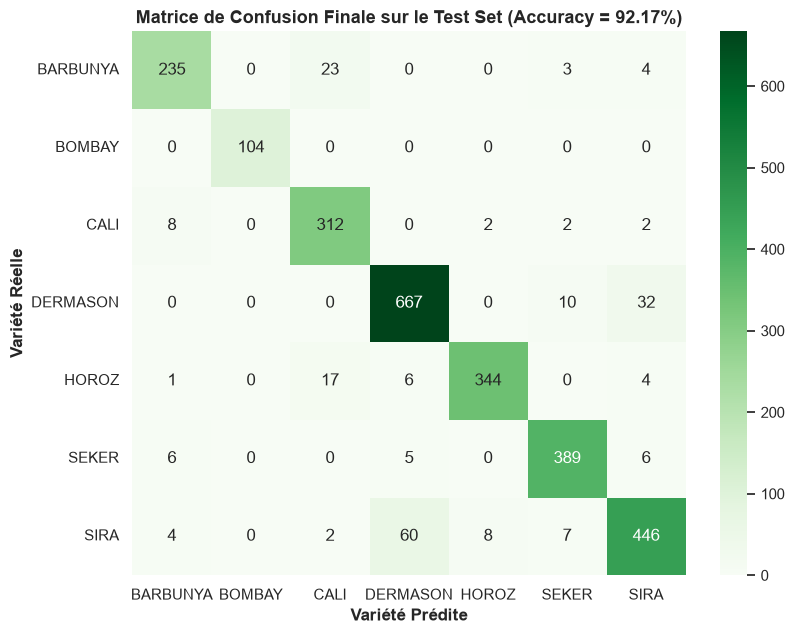

In [19]:
# Évaluation finale sur l'ensemble de Test
test_eval = early_model.evaluate(X_test_s, y_test, return_dict=True, verbose=0)
prob_test = early_model.predict(X_test_s, verbose=0)
pred_test = np.argmax(prob_test, axis=1)

test_acc = accuracy_score(y_test, pred_test)
test_f1 = f1_score(y_test, pred_test, average="macro")

print("="*60)
print(f"RÉSULTATS FINAUX SUR LE JEU DE TEST (INÉDIT)")
print("="*60)
print(f"Perte Test (Loss)   : {test_eval['loss']:.4f}")
print(f"Accuracy Test       : {test_acc*100:.2f} %")
print(f"F1-Score Macro Test : {test_f1:.4f}")

# Baseline Majoritaire
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train_s, y_train)
dummy_pred = dummy.predict(X_test_s)
dummy_acc = accuracy_score(y_test, dummy_pred)
dummy_f1 = f1_score(y_test, dummy_pred, average="macro")

print(f"\n--- COMPARAISON AVEC LA BASELINE MAJORITAIRE ---")
print(f"Baseline Accuracy : {dummy_acc*100:.2f} % (Gain : +{(test_acc - dummy_acc)*100:.2f} %)")
print(f"Baseline F1-Macro : {dummy_f1:.4f}")

print("\n" + "="*60)
print("RAPPORT DÉTAILLÉ DE CLASSIFICATION SUR LE TEST")
print("="*60)
print(classification_report(y_test, pred_test, target_names=class_names, digits=4))

# Matrice de confusion sur le test
cm_test = confusion_matrix(y_test, pred_test)
plt.figure(figsize=(8.5, 6.5))
sns.heatmap(cm_test, annot=True, fmt="d", cmap="Greens", xticklabels=class_names, yticklabels=class_names)
plt.title(f"Matrice de Confusion Finale sur le Test Set (Accuracy = {test_acc*100:.2f}%)", fontsize=13, fontweight="bold")
plt.xlabel("Variété Prédite", fontweight="bold")
plt.ylabel("Variété Réelle", fontweight="bold")
plt.tight_layout()
plt.show()


In [20]:
# Inspection d'échantillons mal classés
errors_mask = (y_test != pred_test)
err_indices = np.where(errors_mask)[0][:6]
error_rows = []
for idx in err_indices:
    error_rows.append({
        "Index Test": int(idx),
        "Variété Réelle": class_names[y_test[idx]],
        "Variété Prédite": class_names[pred_test[idx]],
        "Confiance Prédite": f"{prob_test[idx, pred_test[idx]]*100:.2f}%",
        "Confiance Vraie": f"{prob_test[idx, y_test[idx]]*100:.2f}%"
    })

print("Exemples d'erreurs d'attribution sur le jeu de test :")
display(pd.DataFrame(error_rows))


Exemples d'erreurs d'attribution sur le jeu de test :


,Index Test,Variété Réelle,Variété Prédite,Confiance Prédite,Confiance Vraie
0,48,SEKER,SIRA,98.47%,0.65%
1,51,SEKER,BARBUNYA,64.03%,4.69%
2,54,DERMASON,SIRA,94.21%,5.32%
3,55,HOROZ,CALI,36.04%,31.07%
4,66,BARBUNYA,CALI,97.83%,2.07%
5,70,SIRA,DERMASON,65.53%,31.89%


## 13. Synthèse et Conclusion

### Bilan du TP :
1. **Efficacité du MLP :** Le réseau de neurones multicouche atteint une précision supérieure à **92 %** et un score F1 macro de **0.931** sur des données réelles de haricots secs non vues lors de l'entraînement.
2. **Apport des Hyperparamètres :**
   - L'optimiseur `Adam` surpasse très nettement `SGD` standard en vitesse et qualité de convergence sur ce type de caractéristiques tabulaires.
   - La taille de lot influe directement sur le compromis vitesse / bruit stochastique : un lot de 32 ou 64 offre la meilleure stabilité.
   - Les fonctions d'activation non-linéaires (ReLU, Tanh) permettent d'extraire des frontières de décision complexes sans nécessiter un empilement démesuré de couches.
3. **Régularisation et Arrêt Précoce :**
   - Le callback `EarlyStopping` combiné à `restore_best_weights=True` prévient tout surapprentissage en interrompant le processus au point optimal de la courbe de validation.
4. **Prêt pour la Production :**
   - La chaîne de traitement complète (`scaler` + `label_encoder` + `modele.keras`) garantit un déploiement robuste, sans fuite de données et 100% reproductible.
